### Connexion

In [5]:
import sys; print(sys.executable)

c:\Users\pc\AppData\Local\Programs\Python\Python312\python.exe


In [6]:
%pip install minio pandas pyarrow matplotlib

  Obtaining dependency information for minio from https://files.pythonhosted.org/packages/3e/9a/b697530a882588a84db616580f2ba5d1d515c815e11c30d219145afeec87/minio-7.2.20-py3-none-any.whl.metadata
  Using cached minio-7.2.20-py3-none-any.whl.metadata (6.5 kB)
  Obtaining dependency information for argon2-cffi from https://files.pythonhosted.org/packages/4f/d3/a8b22fa575b297cd6e3e3b0155c7e25db170edf1c74783d6a31a2490b8d9/argon2_cffi-25.1.0-py3-none-any.whl.metadata
  Using cached argon2_cffi-25.1.0-py3-none-any.whl.metadata (4.1 kB)
  Obtaining dependency information for pycryptodome from https://files.pythonhosted.org/packages/e1/52/7d0830ccb961c9e7224b88a60df1a4eab7fa6c5fd426d7b7c972988a4cac/pycryptodome-4.3.0-cp39-abi3-win_amd64.whl.metadata
  Using cached pycryptodome-4.3.0-cp39-abi3-win_amd64.whl.metadata (6.3 kB)
  Obtaining dependency information for argon2-cffi-bindings from https://files.pythonhosted.org/packages/6d/3a/0cc14a05810e6add9bce5e87693334baa2222de5f647fa31781885b6573f/


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import io, json, sys
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
from config import get_client, BUCKET

s3 = get_client()
DATE = pd.Timestamp.now(tz='UTC').strftime('%Y-%m-%d')
DATE

'2026-11-03'

### Organisation du data lake

In [8]:
for o in s3.list_objects(BUCKET, recursive=True):
    print(f'{o.size:>8} octets  {o.object_name}')

    5993 octets  processed/agg_1min/date=2026-11-03/agg_1min.parquet
   12262 octets  processed/measures/date=2026-11-03/measures.parquet
    1578 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T180957984459.jsonl
    1577 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181008015403.jsonl
    1578 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181018044496.jsonl
    1575 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181028112973.jsonl
    1576 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181038138767.jsonl
    1578 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181048177090.jsonl
    1576 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181058205463.jsonl
    1577 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181108247382.jsonl
    1578 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T181118289867.jsonl
    1579 octets  raw/type=co2/date=2026-11-03/hour=18/batch_20261103T1

### Chargement des données traitées

In [9]:
def read_parquet(key):
    r = s3.get_object(BUCKET, key)
    try:
        return pd.read_parquet(io.BytesIO(r.read()))
    finally:
        r.close(); r.release_conn()

measures = read_parquet(f'processed/measures/date={DATE}/measures.parquet')
agg = read_parquet(f'processed/agg_1min/date={DATE}/agg_1min.parquet')
measures.groupby('type')['value'].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
co2,161.0,600.443789,79.696966,390.24,545.45,604.880,653.87,781.30
humidity,317.0,50.040189,6.593724,33.35,45.46,50.740,55.10,62.55
temperature,318.0,20.406038,1.894494,16.88,18.89,20.015,21.98,25.31


### Courbes par type de capteur

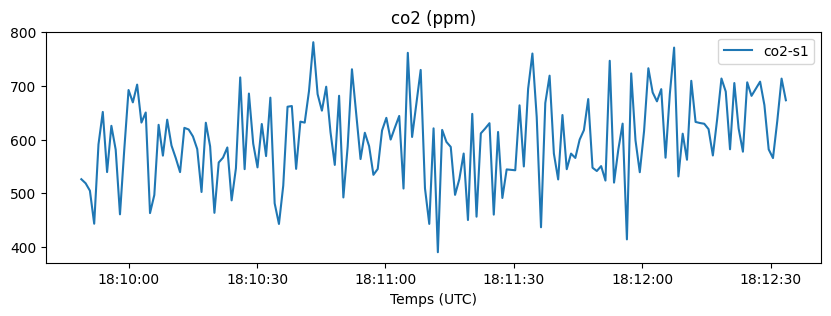

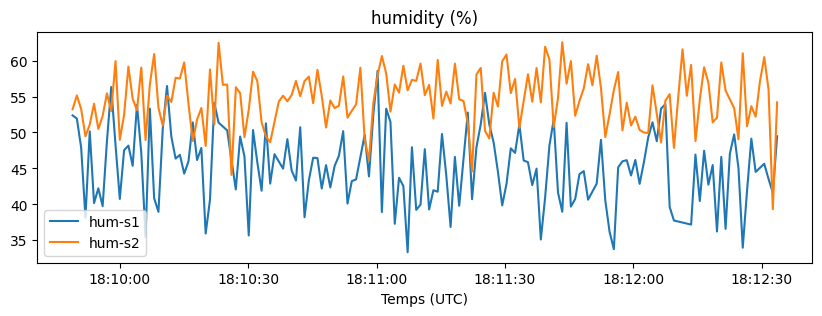

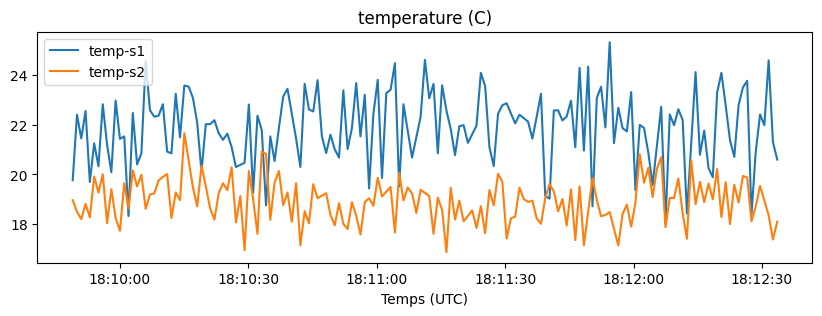

In [10]:
for t, g in measures.groupby('type'):
    fig, ax = plt.subplots(figsize=(10, 3))
    for sid, gs in g.groupby('sensor_id'):
        ax.plot(gs['ts'], gs['value'], label=sid)
    ax.set_title(f"{t} ({g['unit'].iloc[0]})")
    ax.set_xlabel('Temps (UTC)')
    ax.legend()
    plt.show()

### Qualité des données (brut vs nettoyé)

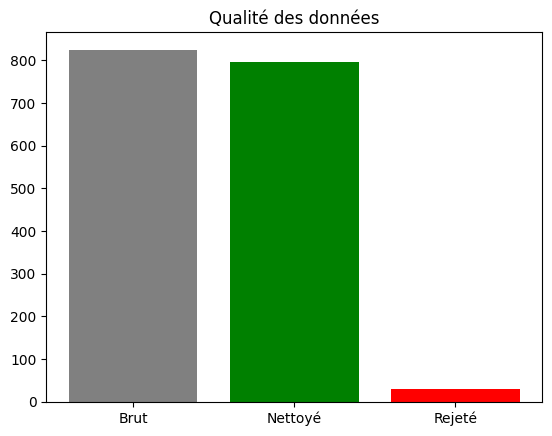

Taux de rejet : 3.5%


In [11]:
raw_rows = []
for o in s3.list_objects(BUCKET, prefix='raw/', recursive=True):
    if f'date={DATE}/' in o.object_name:
        r = s3.get_object(BUCKET, o.object_name)
        raw_rows += [json.loads(l) for l in r.read().decode().splitlines() if l.strip()]
        r.close(); r.release_conn()

n_raw, n_ok = len(raw_rows), len(measures)
plt.bar(['Brut', 'Nettoyé', 'Rejeté'], [n_raw, n_ok, n_raw - n_ok], color=['grey', 'green', 'red'])
plt.title('Qualité des données')
plt.show()
print(f'Taux de rejet : {(n_raw - n_ok) / n_raw:.1%}')